# 03 · Magnifications and light curves

lenscape computes binary-lens magnifications with its own numba code: point source; quadrupole and hexadecapole
approximations near caustics; contour integration of the images on and inside caustics, with linear limb
darkening. A *backend* bundles the accuracy settings.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import config, figures
import time

## Backends

`config.GRID_BACKEND` (loose: the many fits of a map) and `config.REFINE_BACKEND` (tight: best fits, MCMC,
figures). `backend.lc(p, t)` returns the magnification at the times `t` for
p = (t0, u0, tE, log s, log q, α, log ρ).

{'kind': 'nb', 'tol': 0.01, 'reltol': 0.003, 'hexeps': 0.001, 'ctol': 0.1}
{'kind': 'nb', 'tol': 0.001, 'hexeps': 0.0001, 'ctol': 0.01}


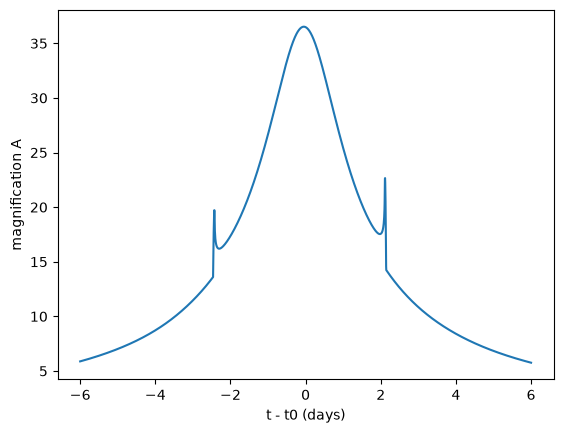

In [2]:
grid = lenscape.make_backend(config.GRID_BACKEND)
tight = lenscape.make_backend(config.REFINE_BACKEND)
print(config.GRID_BACKEND, config.REFINE_BACKEND, sep="\n")

p = np.array([0.0, -0.025, 35.0, 0.002, -2.4, 4.41, -3.3])     # a resonant planetary caustic crossing
t = np.linspace(-6, 6, 3000)
A = tight.lc(p, t)
plt.plot(t, A); plt.xlabel("t - t0 (days)"); plt.ylabel("magnification A");

## Finite source and limb darkening

The source size matters at the caustic crossings: a point source would give infinite magnification. Linear limb
darkening is set per backend (`ld`).

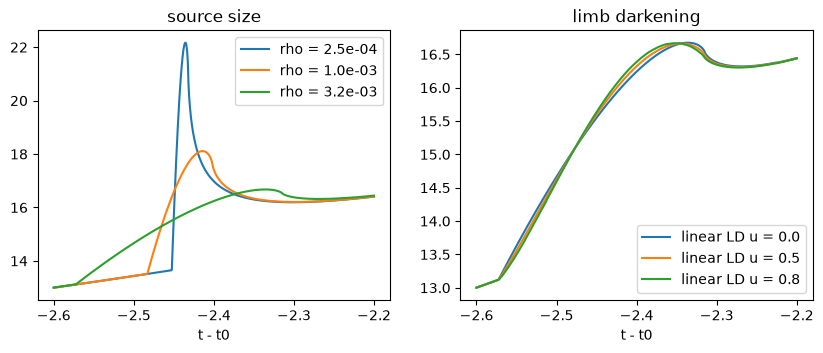

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
tz = np.linspace(-2.6, -2.2, 2000)
for lr in (-3.6, -3.0, -2.5):
    q = p.copy(); q[6] = lr
    ax[0].plot(tz, tight.lc(q, tz), label=f"rho = {10 ** lr:.1e}")
ax[0].legend(); ax[0].set_xlabel("t - t0"); ax[0].set_title("source size")
q = p.copy(); q[6] = -2.5
for ld in (0.0, 0.5, 0.8):
    be = lenscape.make_backend(dict(config.REFINE_BACKEND, ld=ld))
    ax[1].plot(tz, be.lc(q, tz), label=f"linear LD u = {ld}")
ax[1].legend(); ax[1].set_xlabel("t - t0"); ax[1].set_title("limb darkening");

## Speed and accuracy

The loose settings are about 10⁻³ accurate, the tight ones 10⁻⁴ (see `docs/validation.md`). The first call of a
kernel compiles it (cached on disk afterwards), so we time repeated calls.

In [4]:
for name, be in (("grid", grid), ("tight", tight)):
    be.lc(p, t)
    t1 = time.perf_counter(); A_be = be.lc(p, t); dt = time.perf_counter() - t1
    print(f"{name:6s}: {dt * 1e3:6.2f} ms for {len(t)} points, max |A/A_tight - 1| = {np.max(np.abs(A_be / A - 1)):.1e}")

grid  :   4.08 ms for 3000 points, max |A/A_tight - 1| = 4.7e-04
tight :   5.45 ms for 3000 points, max |A/A_tight - 1| = 0.0e+00


## Comparison with VBBinaryLensing (optional)

If [VBBinaryLensing](https://github.com/valboz/VBBinaryLensing) is installed, the two codes can be compared on the
same light curve.

In [5]:
try:
    import VBBinaryLensing
    v = VBBinaryLensing.VBBinaryLensing(); v.Tol, v.RelTol = 1e-4, 1e-4
    t0, u0, tE, ls, lq, al, lr = p
    A_v = np.array(v.BinaryLightCurve([ls * np.log(10), lq * np.log(10), u0, al, lr * np.log(10), np.log(tE), t0],
                                      list(t))[0])
    print("max |A_lenscape / A_VBBL - 1| =", f"{np.max(np.abs(A / A_v - 1)):.1e}")
except ImportError:
    print("VBBinaryLensing is not installed (pip install VBBinaryLensing)")

max |A_lenscape / A_VBBL - 1| = 1.1e-04


## Single lens and binary source

`lenscape.single` has the single-lens magnification (point and finite source, limb darkening) and the
binary-source model, which often competes with a planetary interpretation.

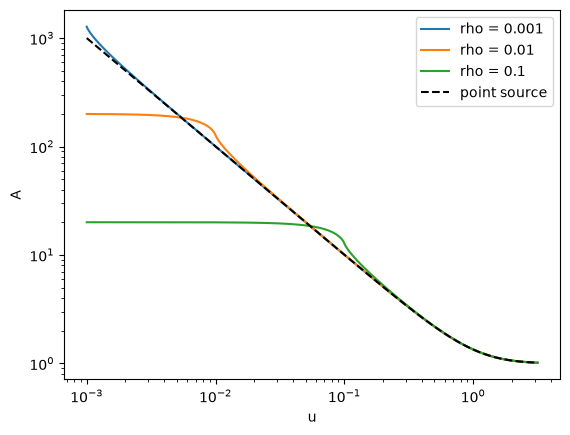

In [6]:
from lenscape import single
u = np.logspace(-3, 0.5, 400)
for rho in (0.001, 0.01, 0.1):                  # espl is a scalar (numba) function
    plt.loglog(u, [single.espl(x, rho) for x in u], label=f"rho = {rho}")
plt.loglog(u, [single.pspl(x) for x in u], "k--", label="point source"); plt.legend()
plt.xlabel("u"); plt.ylabel("A");